In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [2]:
X = df[["petal length (cm)", "petal width (cm)"]]

In [3]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

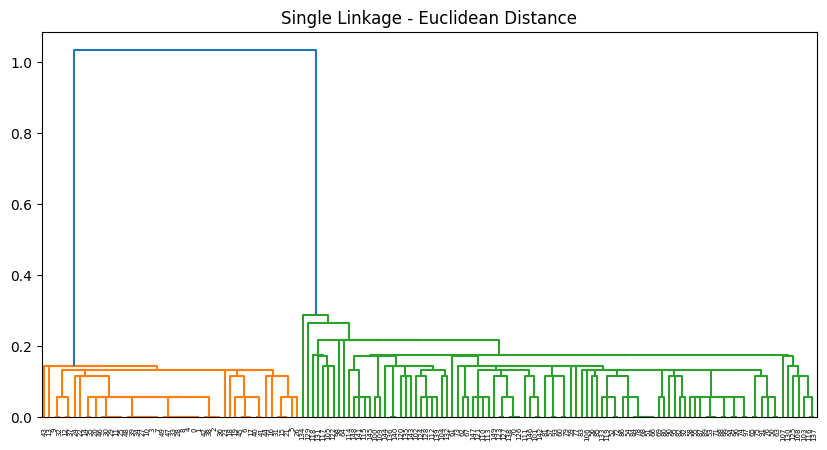

In [4]:
Z = linkage(X_scaled, method="single", metric="euclidean")

plt.figure(figsize=(10,5))
dendrogram(Z)
plt.title("Single Linkage - Euclidean Distance")
plt.show()

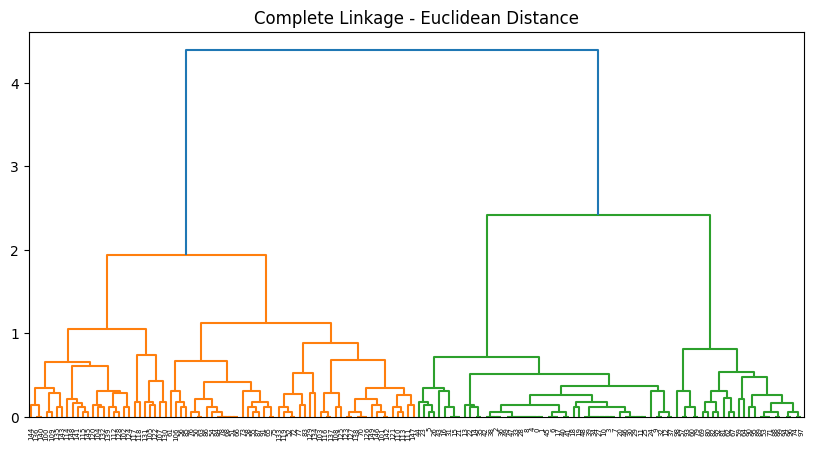

In [6]:
Z = linkage(X_scaled, method="complete", metric="euclidean")

plt.figure(figsize=(10,5))
dendrogram(Z)
plt.title("Complete Linkage - Euclidean Distance")
plt.show()

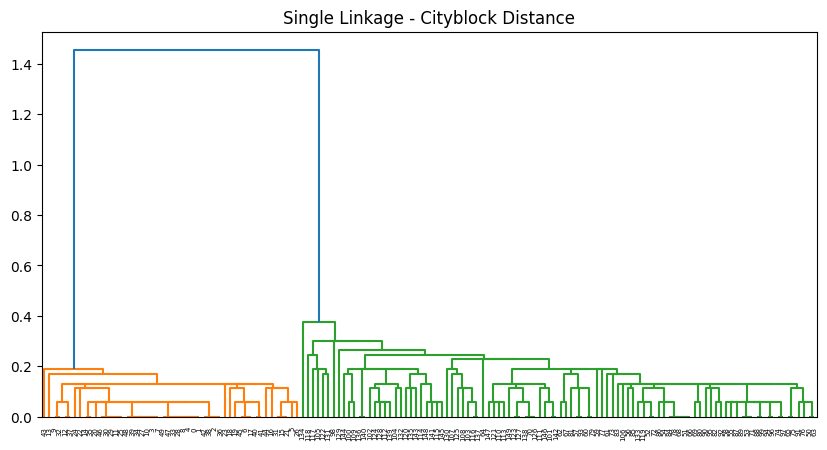

In [7]:
Z = linkage(X_scaled, method="single", metric="cityblock")

plt.figure(figsize=(10,5))
dendrogram(Z)
plt.title("Single Linkage - Cityblock Distance")
plt.show()

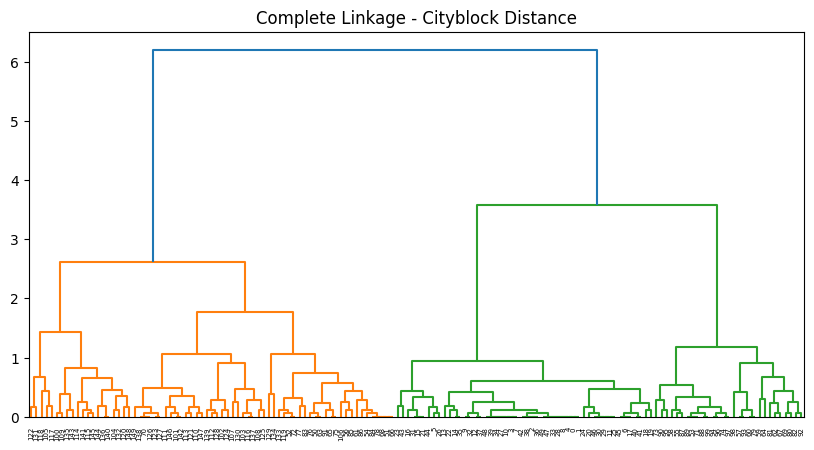

In [8]:
Z = linkage(X_scaled, method="complete", metric="cityblock")

plt.figure(figsize=(10,5))
dendrogram(Z)
plt.title("Complete Linkage - Cityblock Distance")
plt.show()

In [9]:

model = AgglomerativeClustering(
    n_clusters=3,
    linkage="complete",
    metric="euclidean"
)

labels = model.fit_predict(X_scaled)

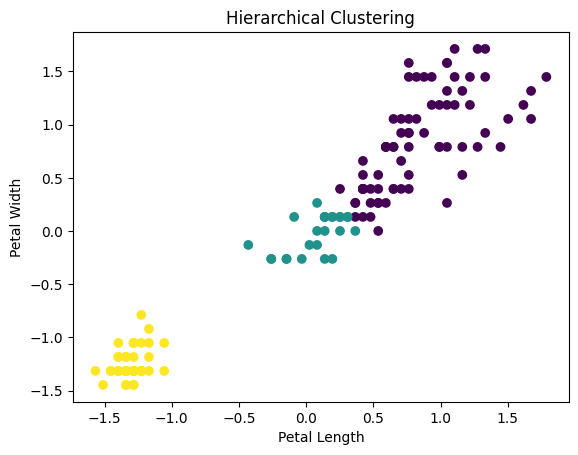

In [10]:
plt.scatter(X_scaled[:,0], X_scaled[:,1], c=labels)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Hierarchical Clustering")

plt.show()

In [11]:

score = silhouette_score(X_scaled, labels)

print("Silhouette Score:", score)

Silhouette Score: 0.5548601998030462


The silhouette score measures how well separated the clusters are. A score closer to 1 indicates strong clustering. The obtained score suggests that the clusters are reasonably well separated, giving confidence in the clustering solution.